In [2]:
import pandas as pd

In [3]:
df=pd.read_csv(r"C:\Users\banu\Downloads\13_17.csv\13_17.csv")

In [4]:
df.head()

,Unnamed: 0,overall,reviewTime,reviewText
0,0,1.0,2014,Exactly what I needed.
1,1,-1.0,2014,"I agree with the other review, the opening is ..."
2,2,1.0,2014,Love these... I am going to order another pack...
3,3,-1.0,2014,too tiny an opening
4,4,0.0,2014,Okay


In [5]:
df.columns.tolist()

['Unnamed: 0', 'overall', 'reviewTime', 'reviewText']

In [6]:
df['overall'].value_counts().sort_index()

overall
-1.0    136959
 0.0     74522
 1.0    468970
Name: count, dtype: int64

In [7]:

import pandas as pd

# Keep a copy of the original dataset
df_clean = df.copy()

print("Original rows:", len(df_clean))

# Remove rows with missing review text or sentiment
df_clean = df_clean.dropna(subset=["reviewText", "overall"])

# Remove reviews containing only spaces
df_clean = df_clean[
    df_clean["reviewText"].astype(str).str.strip().ne("")
].copy()

# Remove duplicate review records
df_clean = df_clean.drop_duplicates(
    subset=["reviewText", "overall"]
).copy()

# Ensure sentiment labels are numeric
df_clean["overall"] = pd.to_numeric(
    df_clean["overall"], errors="coerce"
)

df_clean = df_clean.dropna(subset=["overall"]).copy()

# Keep only the expected sentiment labels
df_clean = df_clean[df_clean["overall"].isin([-1, 0, 1])].copy()

print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("\nSentiment distribution:")
print(df_clean["overall"].value_counts().sort_index())

Original rows: 680451
Rows after cleaning: 616695
Rows removed: 63756

Sentiment distribution:
overall
-1.0    130654
 0.0     72092
 1.0    413949
Name: count, dtype: int64


In [10]:

import re

def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Keep letters, numbers, and spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Create cleaned text for NLP
df_clean["cleaned_text"] = df_clean["reviewText"].apply(clean_text)

# Remove reviews that become empty after cleaning
df_clean = df_clean[df_clean["cleaned_text"].ne("")].copy()

print("Original review:")
print(df_clean["reviewText"].iloc[0])

print("\nCleaned review:")
print(df_clean["cleaned_text"].iloc[0])

print("\nFinal dataset shape:", df_clean.shape)


Original review:
Exactly what I needed.

Cleaned review:
exactly what i needed

Final dataset shape: (616622, 5)


In [8]:

# Remove the extra index column if it exists
df_clean = df_clean.drop(
    columns=["Unnamed: 0", "Id"],
    errors="ignore"
)

print("Columns after removing index:")
print(df_clean.columns.tolist())

display(df_clean.head())


Columns after removing index:
['overall', 'reviewTime', 'reviewText']


,overall,reviewTime,reviewText
0,1.0,2014,Exactly what I needed.
1,-1.0,2014,"I agree with the other review, the opening is ..."
2,1.0,2014,Love these... I am going to order another pack...
3,-1.0,2014,too tiny an opening
4,0.0,2014,Okay


In [9]:

# Input feature: customer review text
X = df_clean["reviewText"].astype(str)

# Target: sentiment label
y = df_clean["overall"].astype(int)

print("Input shape (X):", X.shape)
print("Target shape (y):", y.shape)

print("\nSample review:")
print(X.iloc[0])

print("\nCorresponding sentiment:", y.iloc[0])

print("\nSentiment label counts:")
print(y.value_counts().sort_index())


Input shape (X): (616695,)
Target shape (y): (616695,)

Sample review:
Exactly what I needed.

Corresponding sentiment: 1

Sentiment label counts:
overall
-1    130654
 0     72092
 1    413949
Name: count, dtype: int64


In [10]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))


Training reviews: 493356
Testing reviews: 123339


In [11]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into TF-IDF features
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

# Fit only on training data to prevent data leakage
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


Training TF-IDF shape: (493356, 10000)
Testing TF-IDF shape: (123339, 10000)
Vocabulary size: 10000


In [13]:

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using TF-IDF features and sentiment labels
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [14]:

# Predict sentiment for the test dataset
y_pred = model.predict(X_test_tfidf)

print("First 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])


First 10 actual labels:
[1, 1, 1, 1, 1, 1, 1, 1, 0, -1]

First 10 predicted labels:
[ 1  1  1  1  1  1  1  1 -1 -1]


In [15]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy on the complete test dataset
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Evaluate each sentiment class
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

Model Accuracy: 82.28 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.74      0.79      0.76     26131
     Neutral       0.43      0.17      0.24     14418
    Positive       0.87      0.95      0.91     82790

    accuracy                           0.82    123339
   macro avg       0.68      0.63      0.64    123339
weighted avg       0.79      0.82      0.80    123339



          precision    recall  f1-score
Negative   0.740110  0.785427  0.762096
Neutral    0.427383  0.171036  0.244304
Positive   0.873684  0.948061  0.909354


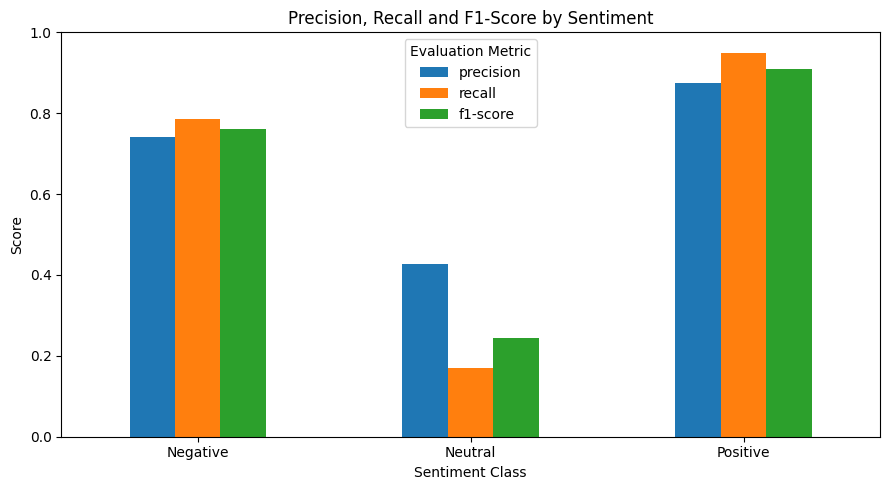

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

scores = pd.DataFrame(report).T.loc[
    ["Negative", "Neutral", "Positive"],
    ["precision", "recall", "f1-score"]
]

print(scores)

scores.plot(kind="bar", figsize=(9, 5))

plt.title("Precision, Recall and F1-Score by Sentiment")
plt.xlabel("Sentiment Class")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

In [18]:
print(scores)

          precision    recall  f1-score
Negative   0.873684  0.948061  0.909354
Neutral    0.000000  0.000000  0.000000
Positive   0.000000  0.000000  0.000000


In [19]:
print("Actual labels:")
print(y_test.value_counts().sort_index())

print("\nPredicted labels:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Actual labels:
overall
-1    26131
 0    14418
 1    82790
Name: count, dtype: int64

Predicted labels:
-1    27731
 0     5770
 1    89838
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

          -1       0.74      0.79      0.76     26131
           0       0.43      0.17      0.24     14418
           1       0.87      0.95      0.91     82790

    accuracy                           0.82    123339
   macro avg       0.68      0.63      0.64    123339
weighted avg       0.79      0.82      0.80    123339



In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

balanced_model.fit(X_train_tfidf, y_train)

y_pred_balanced = balanced_model.predict(X_test_tfidf)

print("Balanced Model Accuracy:",
      round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

Balanced Model Accuracy: 76.44 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.74      0.74     26131
     Neutral       0.31      0.57      0.40     14418
    Positive       0.95      0.81      0.87     82790

    accuracy                           0.76    123339
   macro avg       0.66      0.71      0.67    123339
weighted avg       0.83      0.76      0.79    123339



In [22]:
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

original_report = classification_report(
    y_test, y_pred,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

balanced_report = classification_report(
    y_test, y_pred_balanced,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "Original": {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Neutral Precision": original_report["Neutral"]["precision"],
        "Neutral Recall": original_report["Neutral"]["recall"],
        "Neutral F1": original_report["Neutral"]["f1-score"]
    },
    "Balanced": {
        "Accuracy": accuracy_score(y_test, y_pred_balanced),
        "Neutral Precision": balanced_report["Neutral"]["precision"],
        "Neutral Recall": balanced_report["Neutral"]["recall"],
        "Neutral F1": balanced_report["Neutral"]["f1-score"]
    }
})

print(comparison.round(3))

                   Original  Balanced
Accuracy              0.823     0.764
Neutral Precision     0.427     0.308
Neutral Recall        0.171     0.568
Neutral F1            0.244     0.400


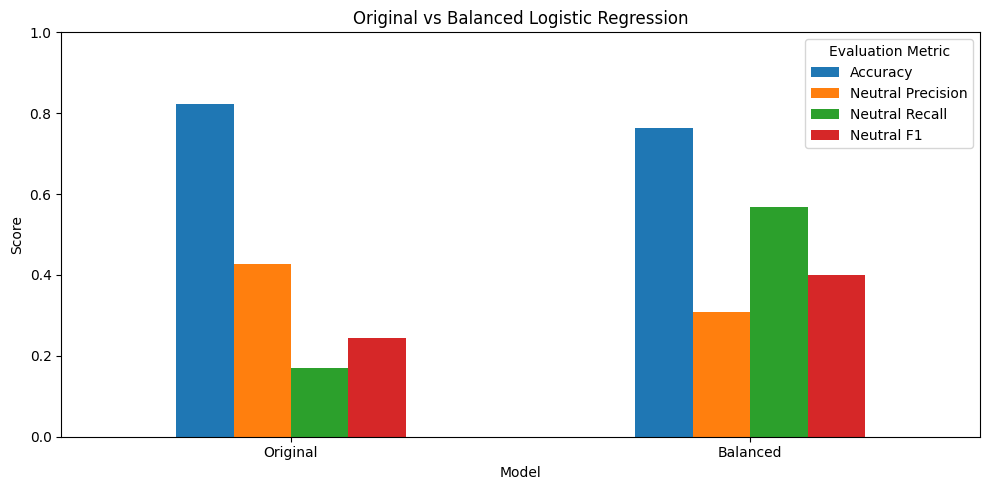

In [23]:
import matplotlib.pyplot as plt

comparison.T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Original vs Balanced Logistic Regression")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# 1. Define the model
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 2. Define hyperparameter values
param_grid = {
    "C": [0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

# 3. Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=2
)

# 4. Train and compare configurations
grid_search.fit(X_train_tfidf, y_train)

# 5. Display the best configuration
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:",
      round(grid_search.best_score_, 4))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Parameters: {'C': 1, 'class_weight': 'balanced'}
Best Cross-Validation Macro F1: 0.6707


In [25]:
from sklearn.metrics import accuracy_score, classification_report

# Get the best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Predict on the untouched test set
y_pred_tuned = best_model.predict(X_test_tfidf)

# Evaluate the tuned model
print(
    "Tuned Model Accuracy:",
    round(accuracy_score(y_test, y_pred_tuned) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

Tuned Model Accuracy: 76.44 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.74      0.74     26131
     Neutral       0.31      0.57      0.40     14418
    Positive       0.95      0.81      0.87     82790

    accuracy                           0.76    123339
   macro avg       0.66      0.71      0.67    123339
weighted avg       0.83      0.76      0.79    123339



In [26]:

# Compare actual sentiment with predicted sentiment

results = pd.DataFrame({
    "Review": X_test.reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "Predicted": y_pred_tuned
})

sentiment_names = {
    -1: "Negative",
     0: "Neutral",
     1: "Positive"
}

results["Actual"] = results["Actual"].map(sentiment_names)
results["Predicted"] = results["Predicted"].map(sentiment_names)

# Display 10 sample predictions
results.head(10)

,Review,Actual,Predicted
0,My grandson finally is potty trained and went ...,Positive,Positive
1,Absolutely amazing,Positive,Positive
2,This bracelet is a good buy for the most part....,Positive,Neutral
3,Love it! Looks great and fits comfortably.,Positive,Positive
4,Beautiful dress. I ordered a size small in US....,Positive,Neutral
5,Absolutely amazing. I was scared that it would...,Positive,Positive
6,Very cozy and comfy. The fabric feels like bab...,Positive,Positive
7,Fit just as expected even after several washes...,Positive,Positive
8,Unfortunately I had to return this item. I gen...,Neutral,Negative
9,Cheap quality material can i give no stars? I ...,Negative,Negative


In [27]:

# Select reviews where the model made a mistake
wrong_predictions = results[
    results["Actual"] != results["Predicted"]
]

print("Total test reviews:", len(results))
print("Incorrect predictions:", len(wrong_predictions))
print(
    "Error rate:",
    round(len(wrong_predictions) / len(results) * 100, 2),
    "%"
)

# Display 10 incorrect predictions
wrong_predictions.head(10)


Total test reviews: 123339
Incorrect predictions: 29055
Error rate: 23.56 %


,Review,Actual,Predicted
2,This bracelet is a good buy for the most part....,Positive,Neutral
4,Beautiful dress. I ordered a size small in US....,Positive,Neutral
8,Unfortunately I had to return this item. I gen...,Neutral,Negative
12,Nice bracelet until you take a shower with it ...,Negative,Neutral
15,it fits about a US small. (large),Neutral,Negative
18,"Product is fine, and what you pay for. It's ul...",Positive,Neutral
21,"The inside fur sticks to my socks, very comfor...",Positive,Neutral
28,"Luckily, I read the reviews so i ordered an XX...",Negative,Neutral
38,smells like a velociraptor,Positive,Negative
42,"I would have given 5 stars, but there is no ta...",Positive,Neutral


In [28]:

from sklearn.metrics import confusion_matrix
import pandas as pd

labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    results["Actual"],
    results["Predicted"],
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Predicted {label}" for label in labels]
)

print("Confusion Matrix:")
display(cm_df)

print("\nTotal incorrect predictions:", len(wrong_predictions))
print(
    "Error rate:",
    round(len(wrong_predictions) / len(results) * 100, 2),
    "%"
)


Confusion Matrix:


,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,19391,5696,1044
Actual Neutral,3763,8190,2465
Actual Positive,3404,12683,66703



Total incorrect predictions: 29055
Error rate: 23.56 %


In [29]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Experiment: include unigrams, bigrams, and trigrams
tfidf_3gram = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 3),
    min_df=2
)

X_train_3gram = tfidf_3gram.fit_transform(X_train)
X_test_3gram = tfidf_3gram.transform(X_test)

model_3gram = LogisticRegression(
    C=1,
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_3gram.fit(X_train_3gram, y_train)
pred_3gram = model_3gram.predict(X_test_3gram)

print("Accuracy:", round(accuracy_score(y_test, pred_3gram) * 100, 2), "%")
print("Macro F1:", round(f1_score(y_test, pred_3gram, average="macro"), 4))


Accuracy: 76.51 %
Macro F1: 0.6697


In [30]:

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

svm_model = LinearSVC(
    C=1,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print(
    "LinearSVC Accuracy:",
    round(accuracy_score(y_test, y_pred_svm) * 100, 2),
    "%"
)

print(
    "LinearSVC Macro F1:",
    round(f1_score(y_test, y_pred_svm, average="macro"), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))


LinearSVC Accuracy: 80.57 %
LinearSVC Macro F1: 0.6715

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.79      0.75     26131
     Neutral       0.37      0.36      0.36     14418
    Positive       0.92      0.89      0.90     82790

    accuracy                           0.81    123339
   macro avg       0.67      0.68      0.67    123339
weighted avg       0.81      0.81      0.81    123339



In [31]:

from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

svm = LinearSVC(
    class_weight="balanced",
    random_state=42
)

param_grid_svm = {
    "C": [0.1, 0.5, 1, 2, 5]
}

svm_grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=2
)

svm_grid.fit(X_train_tfidf, y_train)

print("Best Parameters:", svm_grid.best_params_)
print("Best CV Macro F1:", round(svm_grid.best_score_, 4))


Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters: {'C': 0.1}
Best CV Macro F1: 0.6748


In [32]:

from sklearn.metrics import accuracy_score, f1_score, classification_report

# Get the best model selected by GridSearchCV
best_svm = svm_grid.best_estimator_

# Predict sentiment on unseen test reviews
y_pred_svm_tuned = best_svm.predict(X_test_tfidf)

# Evaluate the model
print(
    "Tuned LinearSVC Accuracy:",
    round(accuracy_score(y_test, y_pred_svm_tuned) * 100, 2),
    "%"
)

print(
    "Tuned LinearSVC Macro F1:",
    round(f1_score(y_test, y_pred_svm_tuned, average="macro"), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm_tuned,
    labels=[-1, 0, 1],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))


Tuned LinearSVC Accuracy: 80.89 %
Tuned LinearSVC Macro F1: 0.6728

Classification Report:
              precision    recall  f1-score   support

    Negative       0.71      0.79      0.75     26131
     Neutral       0.38      0.35      0.36     14418
    Positive       0.92      0.89      0.90     82790

    accuracy                           0.81    123339
   macro avg       0.67      0.68      0.67    123339
weighted avg       0.81      0.81      0.81    123339



In [33]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Original Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro")
    },
    {
        "Model": "Balanced Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_balanced),
        "Macro F1": f1_score(y_test, y_pred_balanced, average="macro")
    },
    {
        "Model": "LinearSVC C=1",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "Macro F1": f1_score(y_test, y_pred_svm, average="macro")
    },
    {
        "Model": "Tuned LinearSVC C=0.1",
        "Accuracy": accuracy_score(y_test, y_pred_svm_tuned),
        "Macro F1": f1_score(y_test, y_pred_svm_tuned, average="macro")
    }
])

comparison["Accuracy"] = (comparison["Accuracy"] * 100).round(2)
comparison["Macro F1"] = comparison["Macro F1"].round(4)

comparison.sort_values("Macro F1", ascending=False)


,Model,Accuracy,Macro F1
3,Tuned LinearSVC C=0.1,80.89,0.6728
2,LinearSVC C=1,80.57,0.6715
1,Balanced Logistic Regression,76.44,0.6692
0,Original Logistic Regression,82.28,0.6386


In [34]:

import joblib

# Save the trained model
joblib.dump(best_svm, "sentiment_model.pkl")

# Save the TF-IDF vectorizer used by this model
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")


Model saved successfully!
TF-IDF vectorizer saved successfully!


In [35]:

import joblib

# Load the saved model and vectorizer
loaded_model = joblib.load("sentiment_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

# New customer reviews
new_reviews = [
    "This product is amazing and works perfectly",
    "The quality is terrible and I am very disappointed",
    "The product is okay, nothing special"
]

# Convert text into TF-IDF features
new_reviews_tfidf = loaded_tfidf.transform(new_reviews)

# Predict sentiment
predictions = loaded_model.predict(new_reviews_tfidf)

# Convert numeric labels into readable names
sentiment_names = {
    -1: "Negative",
     0: "Neutral",
     1: "Positive"
}

for review, prediction in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted sentiment:", sentiment_names[prediction])
    print("-" * 50)


Review: This product is amazing and works perfectly
Predicted sentiment: Positive
--------------------------------------------------
Review: The quality is terrible and I am very disappointed
Predicted sentiment: Negative
--------------------------------------------------
Review: The product is okay, nothing special
Predicted sentiment: Neutral
--------------------------------------------------


In [37]:

import joblib

# Load saved files
loaded_model = joblib.load("sentiment_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

sentiment_names = {
    -1: "Negative",
     0: "Neutral",
     1: "Positive"
}

# Enter a review
review = input("Enter a customer review: ")

# Convert review into TF-IDF features
review_tfidf = loaded_tfidf.transform([review])

# Predict sentiment
prediction = loaded_model.predict(review_tfidf)[0]

print("\nCustomer Review:", review)
print("Predicted Sentiment:", sentiment_names[prediction])


Enter a customer review:  gud product



Customer Review: gud product
Predicted Sentiment: Negative


In [43]:

import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Customer Feedback Intelligence",
    page_icon="💬",
    layout="wide"
)

# Load the trained model and vectorizer
@st.cache_resource
def load_artifacts():
    model = joblib.load("sentiment_model.pkl")
    vectorizer = joblib.load("tfidf_vectorizer.pkl")
    return model, vectorizer

model, vectorizer = load_artifacts()

SENTIMENT_NAMES = {
    -1: "Negative",
     0: "Neutral",
     1: "Positive"
}

# Application header
st.title("💬 Customer Feedback Intelligence")
st.write(
    "Analyze customer reviews using NLP and Machine Learning."
)

st.divider()

# Single-review prediction
st.subheader("🔍 Analyze a Single Review")

review = st.text_area(
    "Enter a customer review",
    placeholder="Example: This product is amazing and works perfectly"
)

if st.button("Analyze Sentiment", key="single_review"):
    if review.strip():
        features = vectorizer.transform([review])
        prediction = int(model.predict(features)[0])

        st.metric(
            "Predicted Sentiment",
            SENTIMENT_NAMES[prediction]
        )
    else:
        st.warning("Please enter a review.")

st.divider()

# Bulk CSV analysis
st.subheader("📁 Analyze Multiple Reviews")
st.write(
    "Upload a CSV file containing a column of customer review text."
)

uploaded_file = st.file_uploader(
    "Upload customer reviews CSV",
    type=["csv"]
)

if uploaded_file is not None:
    try:
        df = pd.read_csv(uploaded_file)

        st.write("Preview of uploaded data")
        st.dataframe(df.head())

        review_column = st.selectbox(
            "Select the column containing review text",
            options=df.columns
        )

        if st.button("Analyze All Reviews"):
            reviews = df[review_column].fillna("").astype(str)
            valid_mask = reviews.str.strip().ne("")

            if not valid_mask.any():
                st.warning("No non-empty reviews were found.")
            else:
                result_df = df.loc[valid_mask].copy()
                valid_reviews = reviews.loc[valid_mask]

                features = vectorizer.transform(valid_reviews)
                predictions = model.predict(features)

                result_df["Predicted Sentiment"] = [
                    SENTIMENT_NAMES[int(pred)]
                    for pred in predictions
                ]

                st.success(
                    f"Analyzed {len(result_df):,} reviews successfully."
                )

                # Sentiment counts
                sentiment_order = [
                    "Positive", "Neutral", "Negative"
                ]

                counts = (
                    result_df["Predicted Sentiment"]
                    .value_counts()
                    .reindex(sentiment_order, fill_value=0)
                )

                total = len(result_df)

                col1, col2, col3 = st.columns(3)

                with col1:
                    st.metric(
                        "Positive Reviews",
                        f"{counts['Positive']:,}",
                        f"{counts['Positive'] / total:.1%}"
                    )

                with col2:
                    st.metric(
                        "Neutral Reviews",
                        f"{counts['Neutral']:,}",
                        f"{counts['Neutral'] / total:.1%}"
                    )

                with col3:
                    st.metric(
                        "Negative Reviews",
                        f"{counts['Negative']:,}",
                        f"{counts['Negative'] / total:.1%}"
                    )

                # Sentiment distribution chart
                st.subheader("Sentiment Distribution")

                fig, ax = plt.subplots()
                counts.plot(kind="bar", ax=ax)
                ax.set_xlabel("Sentiment")
                ax.set_ylabel("Number of Reviews")
                ax.set_title("Customer Feedback Sentiment")
                ax.tick_params(axis="x", rotation=0)

                st.pyplot(fig)
                plt.close(fig)

                # Results table
                st.subheader("Predicted Reviews")
                st.dataframe(
                    result_df,
                    use_container_width=True
                )

                # Download predictions
                csv_data = result_df.to_csv(
                    index=False
                ).encode("utf-8")

                st.download_button(
                    "Download Predictions CSV",
                    data=csv_data,
                    file_name="customer_sentiment_predictions.csv",
                    mime="text/csv"
                )

    except (pd.errors.ParserError, UnicodeDecodeError) as exc:
        st.error(f"Could not read the CSV file: {exc}")
    except Exception as exc:
        st.error(f"Something went wrong: {exc}")


In [44]:
import os

print("Current folder:", os.getcwd())
print("File exists:", os.path.exists(r"C:\Users\banu\nlp_app.py"))

Current folder: C:\Users\banu
File exists: True
